In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore, pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from config import PREPROCESSED, FIGURES, print_versions
print_versions()

P05 = str(PREPROCESSED)
FIG = str(FIGURES)
FS = 125

ch_names = open(os.path.join(P05, "ch_names.txt")).read().split()
train_parts, val_parts, test_parts = range(9), range(9, 12), range(12, 15)

eegs, envs = [], []
for i in range(15):
    e = np.load(os.path.join(P05, f"eeg_part{i:02d}.npy"))
    s = np.load(os.path.join(P05, f"stim_part{i:02d}.npy"))
    n = min(e.shape[1], s.shape[0])
    eegs.append(zscore(e[:, :n], axis=1).T)     # (n, 63)
    envs.append(zscore(s[:n]))                  # (n,)

print(f"{len(eegs)} chapters   {sum(len(e) for e in eegs)} samples   "
      f"{sum(len(e) for e in eegs)/FS/60:.1f} min")

Python 3.12.13 | numpy 2.5.3 | scipy 1.18.1 | sklearn 1.9.0 | mne 1.12.1 | h5py 3.16.0 | matplotlib 3.11.1
15 chapters   297762 samples   39.7 min


best lag 4 samples (32 ms)
  held-out r    0.2312
  held-out MAE  0.8085   null MAE 0.8396


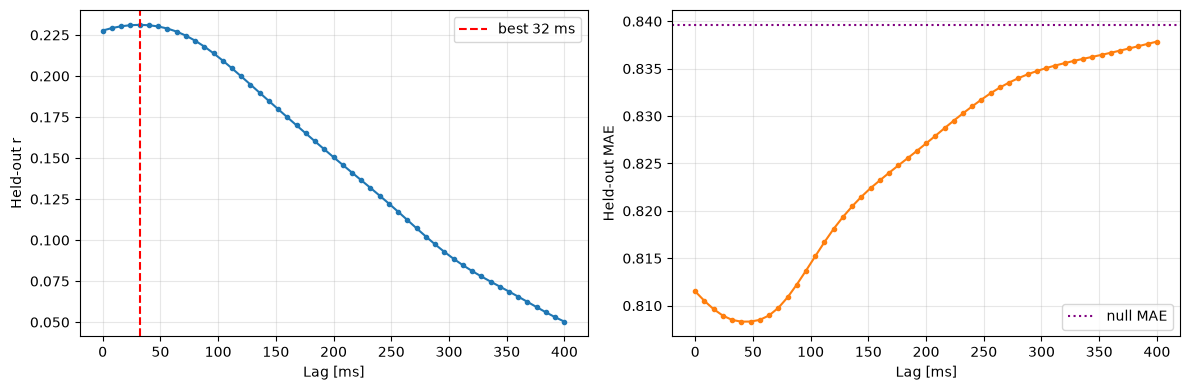

In [2]:
lag_scan = np.arange(0, 51)          # 0 to 400 ms

def lag_xy(parts, L):
    Xs, ys = [], []
    for i in parts:
        e, v = eegs[i], envs[i]
        if L == 0:
            Xs.append(e); ys.append(v)
        else:
            Xs.append(e[L:]); ys.append(v[:-L])   # EEG[t+L] predicts envelope[t]
    return np.vstack(Xs), np.concatenate(ys)

r_lag, mae_lag = [], []
for L in lag_scan:
    Xtr, ytr = lag_xy(train_parts, L)
    Xva, yva = lag_xy(val_parts, L)
    m = LinearRegression().fit(Xtr, ytr)
    p = m.predict(Xva)
    r_lag.append(pearsonr(yva, p)[0])
    mae_lag.append(mean_absolute_error(yva, p))

r_lag, mae_lag = np.array(r_lag), np.array(mae_lag)
best_L = int(lag_scan[r_lag.argmax()])
null_mae = np.mean(np.abs(lag_xy(val_parts, best_L)[1]))

print(f"best lag {best_L} samples ({best_L/FS*1000:.0f} ms)")
print(f"  held-out r    {r_lag.max():.4f}")
print(f"  held-out MAE  {mae_lag[r_lag.argmax()]:.4f}"
      f"   null MAE {null_mae:.4f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(lag_scan/FS*1000, r_lag, marker='o', ms=3)
axs[0].axvline(best_L/FS*1000, c='r', ls='--', label=f'best {best_L/FS*1000:.0f} ms')
axs[0].set_ylabel('Held-out r'); axs[0].legend()
axs[1].plot(lag_scan/FS*1000, mae_lag, marker='o', ms=3, c='tab:orange')
axs[1].axhline(null_mae, c='purple', ls=':', label='null MAE')
axs[1].set_ylabel('Held-out MAE'); axs[1].legend()
for ax in axs:
    ax.set_xlabel('Lag [ms]'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "lag_scan.pdf"), bbox_inches="tight")

injected lag 10 (80 ms)   recovered 10 (80 ms)


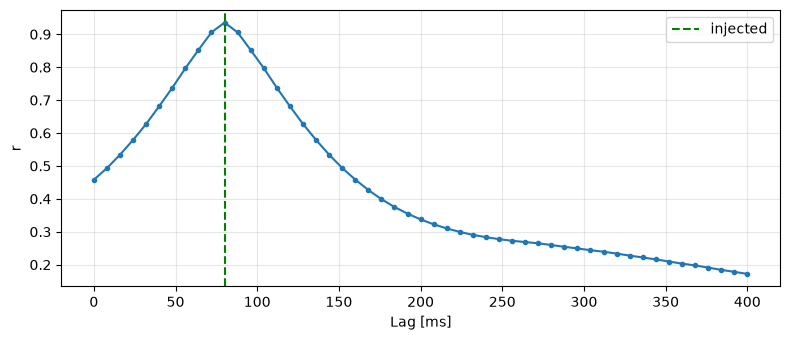

In [3]:
TRUE_LAG = 10                      # 80 ms
rng = np.random.default_rng(0)

fake = []
for i in range(15):
    v = envs[i]; n = len(v)
    f = np.zeros((n, 63))
    resp = np.zeros(n)
    resp[TRUE_LAG:] = v[:-TRUE_LAG]          # EEG[t+10] = envelope[t]
    for c in range(63):
        f[:, c] = resp + rng.normal(0, 3.0, n)
    fake.append(f)

real_eegs = eegs
eegs = fake
r_fake = []
for L in lag_scan:
    Xtr, ytr = lag_xy(train_parts, L)
    Xva, yva = lag_xy(val_parts, L)
    r_fake.append(pearsonr(yva, LinearRegression().fit(Xtr, ytr).predict(Xva))[0])
eegs = real_eegs

r_fake = np.array(r_fake)
print(f"injected lag {TRUE_LAG} ({TRUE_LAG/FS*1000:.0f} ms)   "
      f"recovered {lag_scan[r_fake.argmax()]} "
      f"({lag_scan[r_fake.argmax()]/FS*1000:.0f} ms)")

plt.figure(figsize=(8, 3.5))
plt.plot(lag_scan/FS*1000, r_fake, marker='o', ms=3)
plt.axvline(TRUE_LAG/FS*1000, c='g', ls='--', label='injected')
plt.xlabel('Lag [ms]'); plt.ylabel('r'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "lag_scan_synthetic.pdf"), bbox_inches="tight")

In [4]:
L = best_L
Xtr, ytr = lag_xy(train_parts, L)
Xte, yte = lag_xy(test_parts,  L)

m = LinearRegression().fit(Xtr, ytr)
p = m.predict(Xte)

r_test   = pearsonr(yte, p)[0]
mae_test = mean_absolute_error(yte, p)
null_mae = mean_absolute_error(yte, np.zeros_like(yte))

print(f"single lag {L} ({L/FS*1000:.0f} ms)")
print(f"  test r    {r_test:.4f}")
print(f"  test MAE  {mae_test:.4f}   null {null_mae:.4f}   "
      f"({(null_mae-mae_test)/null_mae*100:.1f}% better)")

per_chapter = []
for i in test_parts:
    Xc, yc = lag_xy([i], L)
    per_chapter.append(pearsonr(yc, m.predict(Xc))[0])
    print(f"  chapter {i}  r {per_chapter[-1]:.4f}")



single lag 4 (32 ms)
  test r    0.2414
  test MAE  0.8241   null 0.8576   (3.9% better)
  chapter 12  r 0.2948
  chapter 13  r 0.2204
  chapter 14  r 0.2175


In [5]:
# Circular-shift null for the single-lag test accuracy
rng = np.random.default_rng(0)
N = 1000
parts_te = [lag_xy([i], L)[1] for i in test_parts]   # test envelope per chapter, one array per chapter
min_shift = 10 * FS                      # keep at least 10 s from the original position

null = np.empty(N)
for k in range(N):
    shifted = np.concatenate([np.roll(t, rng.integers(min_shift, len(t) - min_shift))
                              for t in parts_te])     # shift within each chapter
    null[k] = pearsonr(shifted, p)[0]

pval = (np.sum(null >= r_test) + 1) / (N + 1)
print(f"test r     {r_test:.4f}")
print(f"null mean  {null.mean():.4f}")
print(f"null 95th  {np.percentile(null, 95):.4f}")
print(f"p          {pval:.4f}")

test r     0.2414
null mean  -0.0001
null 95th  0.0327
p          0.0010


lag 4 (32 ms)   train (185351, 63)   6 held-out chapters
loaded from cache
  LinearRegression   MAE 0.8159 ± 0.0098   r 0.2380
  RandomForest       MAE 0.8241 ± 0.0118   r 0.1932
  KernelRidge RBF    MAE 0.8193 ± 0.0155   r 0.2249

null MAE 0.8484
KernelRidge RBF trained on 20000 subsampled points — not directly comparable
best: LinearRegression   MAE 0.8159   beats null by 3.8%
linear baseline 0.8159   margin +0.0000


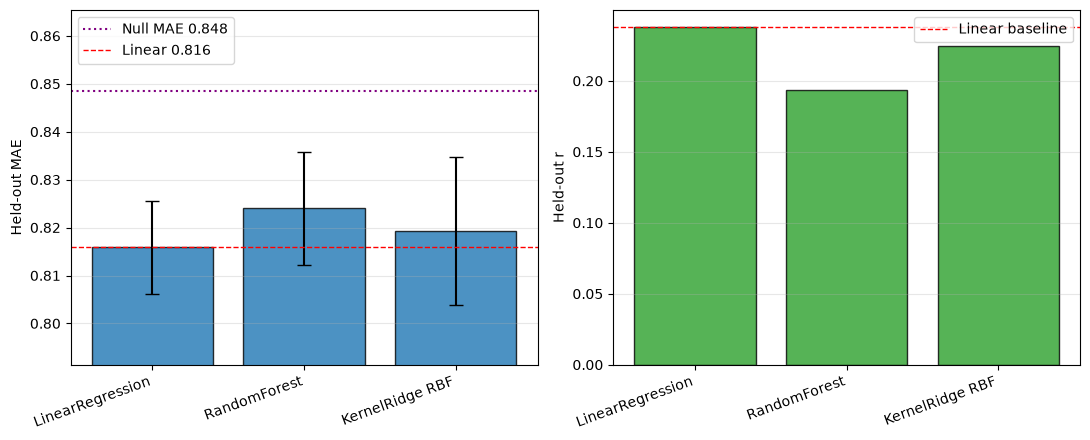

In [6]:
from sklearn.kernel_ridge import KernelRidge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

L = best_L
held_out = list(range(9, 15))          # chapters 9-14, six folds

Xtr, ytr = lag_xy(train_parts, L)
print(f"lag {L} ({L/FS*1000:.0f} ms)   train {Xtr.shape}   {len(held_out)} held-out chapters")

SUB = 20000
rng = np.random.default_rng(0)
sub = rng.choice(len(Xtr), SUB, replace=False)

models = [
    ("LinearRegression", LinearRegression(),                              False),
    ("RandomForest",     RandomForestRegressor(n_estimators=200, n_jobs=-1,
                                               random_state=0),           False),
    ("KernelRidge RBF",  make_pipeline(StandardScaler(),
                            KernelRidge(kernel="rbf", alpha=1.0)),        True),
]

CACHE = os.path.join(P05, "cache")
os.makedirs(CACHE, exist_ok=True)
RECOMPUTE = False          #set True to refit the models instead of loading the cached results
cache_file = os.path.join(CACHE, f"nonlinear_L{L}_sub{SUB}_n{len(models)}.npz")

if os.path.exists(cache_file) and not RECOMPUTE:
    d = np.load(cache_file)
    names = list(d["names"])
    mae_mean, mae_sd, r_mean = list(d["mae_mean"]), list(d["mae_sd"]), list(d["r_mean"])
    print("loaded from cache")
else:
    names, mae_mean, mae_sd, r_mean = [], [], [], []
    for name, m, subsample in models:
        m.fit(Xtr[sub], ytr[sub]) if subsample else m.fit(Xtr, ytr)

        f_mae, f_r = [], []
        for i in held_out:
            Xc, yc = lag_xy([i], L)
            p = m.predict(Xc)
            f_mae.append(mean_absolute_error(yc, p))
            f_r.append(pearsonr(yc, p)[0])

        names.append(name)
        mae_mean.append(np.mean(f_mae)); mae_sd.append(np.std(f_mae))
        r_mean.append(np.mean(f_r))
    np.savez(cache_file, names=names, mae_mean=mae_mean, mae_sd=mae_sd, r_mean=r_mean)
    print(f"computed and saved to {os.path.basename(cache_file)}")

for k in range(len(names)):
    print(f"  {names[k]:<18} MAE {mae_mean[k]:.4f} ± {mae_sd[k]:.4f}   r {r_mean[k]:.4f}")

null_mae = np.mean([mean_absolute_error(lag_xy([i], L)[1],
                    np.zeros(len(lag_xy([i], L)[1]))) for i in held_out])
mae_mean, mae_sd = np.array(mae_mean), np.array(mae_sd)

print(f"\nnull MAE {null_mae:.4f}")
print(f"KernelRidge RBF trained on {SUB} subsampled points — not directly comparable")
best = int(mae_mean.argmin())
print(f"best: {names[best]}   MAE {mae_mean[best]:.4f}   "
      f"beats null by {(null_mae-mae_mean[best])/null_mae*100:.1f}%")
print(f"linear baseline {mae_mean[0]:.4f}   "
      f"margin {mae_mean[0]-mae_mean[best]:+.4f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))

x = np.arange(len(names))
axs[0].bar(x, mae_mean, yerr=mae_sd, capsize=5, color='tab:blue',
           alpha=0.8, edgecolor='k')
axs[0].axhline(null_mae, c='purple', ls=':', lw=1.5, label=f'Null MAE {null_mae:.3f}')
axs[0].axhline(mae_mean[0], c='r', ls='--', lw=1, label=f'Linear {mae_mean[0]:.3f}')
axs[0].set_xticks(x); axs[0].set_xticklabels(names, rotation=20, ha='right')
axs[0].set_ylabel('Held-out MAE')
axs[0].set_ylim(min(mae_mean)*0.97, null_mae*1.02)
axs[0].legend(loc="upper left"); axs[0].grid(axis='y', alpha=0.3)

axs[1].bar(x, r_mean, color='tab:green', alpha=0.8, edgecolor='k')
axs[1].axhline(r_mean[0], c='r', ls='--', lw=1, label='Linear baseline')
axs[1].set_xticks(x); axs[1].set_xticklabels(names, rotation=20, ha='right')
axs[1].set_ylabel('Held-out r')
axs[1].legend(); axs[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIG, "nonlinear.pdf"), bbox_inches="tight")